# random forest vs xgboost

predicting house price with a random forest and with xgboost. cleaned data comes from `eda.ipynb`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
SEED = 42

## 1. load data and hold out one listing

one random listing is taken out before any split. it is not used for training, tuning or testing, and i use it at the end to try the saved model on a house it has never seen.

In [2]:
df = pd.read_csv('../data/processed/houses_clean.csv')
df['is_member'] = df['is_member'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})
print(df.shape)

holdout = df.sample(1, random_state=SEED)
df = df.drop(holdout.index).reset_index(drop=True)
print('rows left for training and testing:', len(df))

features = ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches', 'posted_month',
            'is_verified', 'location', 'district', 'membership_level', 'is_member']
X = df[features]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(27723, 11)
rows left for training and testing: 27722
(22177, 10) (5545, 10)


## 2. preprocessing

all of this sits in one `ColumnTransformer`, so it is fitted on the training rows only.

- numbers: fill missing with the median, `log1p` on house size and land size (both skewed), then standard scaling
- categories (location, district, membership): fill with the most common value and one hot encode. locations with fewer than 30 ads go into one rare group, and a location the model has never seen at prediction time falls into that group too
- target: price is skewed, so the model learns `log(price)` and the result is turned back into rupees

scaling does nothing for trees, but it is cheap and keeps the pipeline general.

In [3]:
log_cols = ['house_size_sqft', 'land_size_perches']
other_num = ['bedrooms', 'bathrooms', 'posted_month', 'is_verified', 'is_member']
cat_cols = ['location', 'district', 'membership_level']

preprocess = ColumnTransformer([
    ('log_num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler()),
    ]), log_cols),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]), other_num),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False)),
    ]), cat_cols),
])

def make_pipeline(regressor):
    model = TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([('prep', preprocess), ('model', model)])

width = preprocess.fit(X_train).get_feature_names_out().shape[0]
print('features after preprocessing:', width)

features after preprocessing: 116


## 3. default random forest and xgboost

both with default parameters, scored on the same 20% test set. rmsle and r2 are on log price, mae is in millions of rupees and the last column is the median error as a percent of the real price.

In [4]:
def evaluate(pipe):
    pred = pipe.predict(X_test)
    log_t, log_p = np.log1p(y_test), np.log1p(pred)
    return {
        'rmsle': mean_squared_error(log_t, log_p) ** 0.5,
        'r2 (log)': r2_score(log_t, log_p),
        'mae (rs m)': mean_absolute_error(y_test, pred) / 1e6,
        'median abs % error': (np.abs(pred - y_test) / y_test).median() * 100,
    }

rf_default = make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)
xgb_default = make_pipeline(XGBRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)

models = {'random forest (default)': rf_default, 'xgboost (default)': xgb_default}
pd.DataFrame({name: evaluate(m_) for name, m_ in models.items()}).T.round(3)

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.43
xgboost (default),0.389,0.783,8.245,18.78


with the reposts removed the score is worse than before (rmsle 0.392 for the forest, it was 0.349), and this is the honest number. xgboost is a little better on rmsle (0.389) but the forest has the lower median error (15.4% against 18.8%). they are very close, so tuning is next.

## 4. choosing the parameters

defaults are made for general data, so i set the main ones myself.

**random forest**
- `n_estimators` 150, fixed. more trees only lower the variance a bit
- `max_depth` 14 to unlimited, unlimited trees memorise noise
- `min_samples_leaf` 3, 5 or 8. ads are noisy, a leaf of 1 just copies one ad
- `max_features` 0.33 to 1.0, there are many one hot columns

**xgboost**
- `learning_rate` 0.05 to 0.1, small steps overfit less
- `max_depth` 4 to 8, boosting wants shallow trees
- `subsample` and `colsample_bytree` below 1 add randomness
- `n_estimators` from early stopping, next cell

best number of rounds: 673


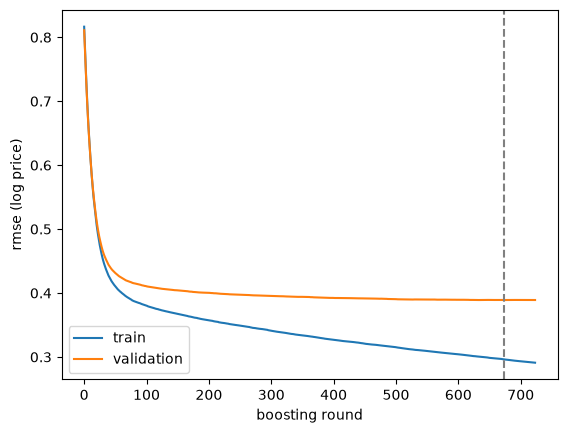

In [5]:
# how many boosting rounds are needed at lr 0.05 and depth 6?
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
prep_tmp = clone(preprocess).fit(X_tr)

probe = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8,
                     colsample_bytree=0.7, early_stopping_rounds=50, tree_method='hist', random_state=SEED, n_jobs=-1)
probe.fit(prep_tmp.transform(X_tr), np.log1p(y_tr),
          eval_set=[(prep_tmp.transform(X_tr), np.log1p(y_tr)), (prep_tmp.transform(X_val), np.log1p(y_val))],
          verbose=False)
history = probe.evals_result()
print('best number of rounds:', probe.best_iteration)

plt.plot(history['validation_0']['rmse'], label='train')
plt.plot(history['validation_1']['rmse'], label='validation')
plt.axvline(probe.best_iteration, color='grey', linestyle='--')
plt.xlabel('boosting round')
plt.ylabel('rmse (log price)')
plt.legend()
plt.show()

## 4. tuning

randomized search with 3 fold cross validation on the training set. the score is rmsle (rmse on log price), so a 10% miss counts the same for a 5 million house and a 100 million one.

In [6]:
kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
score = 'neg_root_mean_squared_log_error'

rf_space = {
    'model__regressor__max_depth': [14, 18, 24, None],
    'model__regressor__min_samples_leaf': [3, 5, 8],
    'model__regressor__max_features': [0.33, 0.5, 0.7, 1.0],
}
rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1))
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=6, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
rf_search.fit(X_train, y_train)
print('rf best cv rmsle:', round(-rf_search.best_score_, 4))
print(rf_search.best_params_)

rf best cv rmsle: 0.4006
{'model__regressor__min_samples_leaf': 3, 'model__regressor__max_features': 0.33, 'model__regressor__max_depth': 24}


In [7]:
BEST_ROUNDS = probe.best_iteration

xgb_space = {
    'model__regressor__n_estimators': [int(BEST_ROUNDS * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.05, 0.08, 0.1],
    'model__regressor__max_depth': [4, 6, 8],
    'model__regressor__subsample': [0.7, 0.85, 1.0],
    'model__regressor__colsample_bytree': [0.5, 0.7, 0.9],
}
xgb_pipe = make_pipeline(XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1))
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=8, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
xgb_search.fit(X_train, y_train)
print('xgb best cv rmsle:', round(-xgb_search.best_score_, 4))
print(xgb_search.best_params_)

xgb best cv rmsle: 0.3884
{'model__regressor__subsample': 0.7, 'model__regressor__n_estimators': 673, 'model__regressor__max_depth': 8, 'model__regressor__learning_rate': 0.05, 'model__regressor__colsample_bytree': 0.5}


In [8]:
rf_best = rf_search.best_estimator_
xgb_best = xgb_search.best_estimator_

models = {
    'random forest (default)': rf_default,
    'xgboost (default)': xgb_default,
    'random forest (tuned)': rf_best,
    'xgboost (tuned)': xgb_best,
}
pd.DataFrame({name: evaluate(m_) for name, m_ in models.items()}).T.round(3)

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.430
xgboost (default),0.389,0.783,8.245,18.780
random forest (tuned),0.390,0.782,8.220,17.061
xgboost (tuned),0.376,0.798,7.841,17.294


tuning helped xgboost more. its rmsle goes from 0.389 to 0.376 while the forest only goes from 0.392 to 0.390. the tuned forest has a higher median error than the default one (17.1% against 15.4%), xgboost is a bit lower (17.3% against 18.8%). the search grids are small, i may widen them later.